# Mini-Jev · v2: Distillation on Jev's full probabilities

**The one question this notebook answers:** v1 learned Jev's answers but ended up 15 points overconfident (claims 78%, worth 63%). If the student learns Jev's **full** probabilities instead of only the top answer, does that gap close?

**Fair-comparison rule:** everything is identical to v1: same base model, same LoRA settings, same 19,393 rows in the same order, same steps, same exam. **Only the loss function changes.** That's what makes any difference attributable to the loss.

**Two additions that make the result credible:**
1. **Temperature scaling baseline.** A skeptic will ask: "Couldn't you just fix v1's overconfidence after training with one number?" We test that directly.
2. **Confidence intervals.** We check whether v2's differences from v1 are bigger than luck.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U transformers accelerate peft bitsandbytes

name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 71.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.9 MB/s eta 0:00:00


In [2]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-1.7B"
SAVE_DIR = "/content/drive/MyDrive/mini-jev"
RUN_NAME = "v2"

# Must match v1 exactly, or the comparison isn't fair
N_TRAIN_USE = None
N_VAL = 500
MAX_LEN = 640
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LR = 2e-4
MICRO_BATCH, ACCUM = 8, 4
WARMUP_FRAC = 0.03
LOG_EVERY, VAL_EVERY, SAVE_EVERY = 10, 100, 50

In [3]:
import os, re, time
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

for f in ["train_20k.parquet", "eval_2k.parquet", "preds_v0.parquet", "preds_v1.parquet", "results.csv", "v1_adapter"]:
    assert os.path.exists(f"{SAVE_DIR}/{f}"), f"Missing {f}: run the earlier notebooks first"
train_all = pd.read_parquet(f"{SAVE_DIR}/train_20k.parquet")
eval_s = pd.read_parquet(f"{SAVE_DIR}/eval_2k.parquet")
preds_v1 = pd.read_parquet(f"{SAVE_DIR}/preds_v1.parquet")
assert list(preds_v1["id"]) == list(eval_s["id"])
results = pd.read_csv(f"{SAVE_DIR}/results.csv")
V1_ROWS = int(re.search(r"(\d+) rows", results.loc[results["version"] == "v1", "method"].iloc[0]).group(1))
print(len(train_all), "train rows |", len(eval_s), "eval rows | v1 trained on", V1_ROWS, "rows")

Mounted at /content/drive
19996 train rows | 1998 eval rows | v1 trained on 19393 rows


## Helpers (identical to v1)

In [4]:
LETTERS = "ABCDEFGHIJKLMNOP"
INSTRUCTION = ("You are a decision model. Read the situation and the question, "
               "then answer with the single letter of the best option.")

def format_user_message(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}\n\nAnswer with one letter.")

def kl_div(q, p, eps=1e-9):
    q, p = np.asarray(q, float), np.asarray(p, float)
    return float(np.sum(q * (np.log(q + eps) - np.log(p + eps))))

def calibration_bins(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    rows = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            rows.append({"bin_lo": i / n_bins, "bin_hi": (i + 1) / n_bins, "n": int(m.sum()),
                         "mean_conf": float(conf[m].mean()), "mean_acc": float(correct[m].mean())})
    bins = pd.DataFrame(rows)
    ece = float((bins["n"] / len(conf) * (bins["mean_acc"] - bins["mean_conf"]).abs()).sum())
    return ece, bins

def evaluate(preds, targets, n_bins=10):
    conf, soft, hard, kls, briers = [], [], [], [], []
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        conf.append(p[a]); soft.append(q[a]); hard.append(float(a == int(np.argmax(q))))
        kls.append(kl_div(q, p)); briers.append(float(np.sum((p - q) ** 2)))
    ece, bins = calibration_bins(conf, soft, n_bins)
    return {"n": len(conf), "agreement": float(np.mean(hard)), "expected_acc": float(np.mean(soft)),
            "mean_conf": float(np.mean(conf)), "ece": ece, "kl": float(np.mean(kls)),
            "brier": float(np.mean(briers))}, bins

def per_kind_table(preds, df):
    out = []
    for kind, g in df.groupby("kind"):
        idx = np.flatnonzero(df["kind"].to_numpy() == kind)
        m, _ = evaluate([preds[i] for i in idx], g["target"])
        out.append({"kind": kind, **m})
    return pd.DataFrame(out)

def letter_picks(preds, df):
    # share of rows where each letter was the top pick, per kind: the position-bias check
    pred = [LETTERS[int(np.argmax(p))] for p in preds]
    jev = [LETTERS[int(np.argmax(t))] for t in df["target"]]
    out = {}
    for kind in sorted(df["kind"].unique()):
        m = (df["kind"] == kind).to_numpy()
        out[kind] = {"model": pd.Series(np.array(pred)[m]).value_counts(normalize=True).round(2).to_dict(),
                     "jev": pd.Series(np.array(jev)[m]).value_counts(normalize=True).round(2).to_dict()}
    return out

In [5]:
import matplotlib.pyplot as plt

def reliability_panels(panels, path=None):
    # small multiples: one panel per version, shared axes; each panel is one series, titled, so no legend needed
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.4), dpi=120, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (title, bins) in zip(axes, panels):
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=1.5, ls="--", zorder=1)
        width = (bins["bin_hi"] - bins["bin_lo"]) - 0.012
        ax.bar(bins["bin_lo"] + 0.006, bins["mean_acc"], width=width, align="edge", color="#3b6fb6", zorder=2)
        for _, r in bins.iterrows():
            ax.text(r["bin_lo"] + 0.05, min(r["mean_acc"] + 0.02, 0.96), f"n={int(r['n'])}", ha="center", fontsize=6.5, color="#555")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title(title, fontsize=10.5, loc="left")
        ax.set_xlabel("Model confidence (top option)")
        ax.grid(color="#e6e6e6", lw=0.8, zorder=0); ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes[0].set_ylabel("Expected accuracy vs. Jev")
    axes[0].text(0.96, 0.89, "perfect calibration", color="#6b6b6b", fontsize=7.5, ha="right", rotation=45, rotation_mode="anchor")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

## New tools: temperature scaling and confidence intervals

**Temperature scaling** (Guo et al. 2017) is the standard after-the-fact calibration fix. Take the model's log-probabilities, divide by one number T, re-normalize. **T > 1 softens** the distribution (less confident); T < 1 sharpens it. We pick the T that makes predictions closest to Jev on the **validation rows**, never the exam.

It never changes which option is on top, so **agreement stays the same**; only confidence moves. If temperature scaling fixes v1 as well as distillation does, distillation's advantage is mostly cosmetic. That's an honest result worth reporting either way.

**Paired bootstrap:** resample the 2,000 exam rows with replacement 2,000 times, recompute "v2 minus v1" each time, and take the middle 95% of those differences. If that range doesn't include 0, the difference is unlikely to be luck. "Paired" means both models are scored on the *same* resampled rows each time, which cancels out row difficulty.

In [6]:
def apply_temperature(dists, T):
    out = []
    for p in dists:
        z = np.log(np.clip(np.asarray(p, float), 1e-12, 1.0)) / T
        z -= z.max()
        e = np.exp(z)
        out.append(e / e.sum())
    return out

def fit_temperature(dists, targets, grid=np.round(np.arange(0.5, 5.01, 0.05), 2)):
    targets = [np.asarray(t, float) for t in targets]
    scores = [np.mean([kl_div(q, p) for p, q in zip(apply_temperature(dists, T), targets)]) for T in grid]
    return float(grid[int(np.argmin(scores))])

def row_stats(preds, targets):
    s = {k: [] for k in ["conf", "soft", "hard", "kl", "brier"]}
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        s["conf"].append(p[a]); s["soft"].append(q[a]); s["hard"].append(float(a == int(np.argmax(q))))
        s["kl"].append(kl_div(q, p)); s["brier"].append(float(np.sum((p - q) ** 2)))
    return {k: np.array(v) for k, v in s.items()}

def ece_fast(conf, soft, n_bins=10):
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    return float(np.abs(np.bincount(b, soft, n_bins) - np.bincount(b, conf, n_bins)).sum() / len(conf))

def paired_bootstrap(stats_a, stats_b, n_boot=2000, seed=0):
    # CI for (b - a) on each metric. Negative is better for ece/kl/brier, positive is better for agreement.
    rng = np.random.default_rng(seed)
    n = len(stats_a["conf"])
    metrics = {"agreement": lambda s, i: s["hard"][i].mean(), "ece": lambda s, i: ece_fast(s["conf"][i], s["soft"][i]),
               "kl": lambda s, i: s["kl"][i].mean(), "brier": lambda s, i: s["brier"][i].mean()}
    all_i = np.arange(n)
    rows = []
    for name, f in metrics.items():
        diffs = []
        for _ in range(n_boot):
            i = rng.integers(0, n, n)
            diffs.append(f(stats_b, i) - f(stats_a, i))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"metric": name, "diff": f(stats_b, all_i) - f(stats_a, all_i), "ci_low": lo, "ci_high": hi,
                     "real?": "yes" if (lo > 0 or hi < 0) else "no (could be luck)"})
    return pd.DataFrame(rows)

# Load the base model, rebuild v1's exact data split

In [7]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_cosine_schedule_with_warmup
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training, set_peft_model_state_dict
from safetensors.torch import load_file

DEVICE = "cuda"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16, device_map={"": 0})
base.config.use_cache = False

LETTER_IDS = []
for L in LETTERS:
    ids = tok.encode(L, add_special_tokens=False)
    assert len(ids) == 1
    LETTER_IDS.append(ids[0])

def build_prompt(row):
    msgs = [{"role": "user", "content": format_user_message(row)}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def answer_logits(model, prompts):
    enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    pos = (enc.attention_mask.cumsum(-1) - 1).clamp(min=0)
    try:
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos, logits_to_keep=1)
    except TypeError:
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos)
    return out.logits[:, -1, :]

@torch.no_grad()
def predict_distributions(model, prompts, ks, batch_size=16):
    was_training = model.training
    model.eval()
    order = np.argsort([len(p) for p in prompts])
    dists, mass = [None] * len(prompts), [None] * len(prompts)
    for s in range(0, len(prompts), batch_size):
        idx = order[s:s + batch_size]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = answer_logits(model, [prompts[i] for i in idx]).float()
        full = torch.softmax(logits, dim=-1)
        for j, i in enumerate(idx):
            ids = LETTER_IDS[:ks[i]]
            dists[i] = torch.softmax(logits[j, ids], dim=-1).cpu().numpy()
            mass[i] = float(full[j, ids].sum())
    if was_training:
        model.train()
    return dists, np.array(mass)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [8]:
train_df = train_all if N_TRAIN_USE is None else train_all.sample(N_TRAIN_USE, random_state=SEED)
train_df = train_df.reset_index(drop=True)
prompts = [build_prompt(r) for r in train_df.to_dict("records")]
lengths = np.array([len(x) for x in tok(prompts, add_special_tokens=True)["input_ids"]])
keep = lengths <= MAX_LEN
rows = [{"prompt": p, "target": np.asarray(t, float), "kind": k}
        for p, t, k, ok in zip(prompts, train_df["target"], train_df["kind"], keep) if ok]
perm = np.random.default_rng(SEED).permutation(len(rows))
val_rows = [rows[i] for i in perm[:N_VAL]]
train_rows = [rows[i] for i in perm[N_VAL:]]
assert len(train_rows) == V1_ROWS, f"Data differs from v1 ({len(train_rows)} vs {V1_ROWS}): check the config matches v1"
val_prompts = [r["prompt"] for r in val_rows]
val_ks = [len(r["target"]) for r in val_rows]
val_targets = [r["target"] for r in val_rows]
eval_prompts = [build_prompt(r) for r in eval_s.to_dict("records")]
eval_ks = [len(o) for o in eval_s["options"]]
print(f"Same split as v1 ✓  {len(train_rows)} train | {len(val_rows)} val")

Same split as v1 ✓  19393 train | 500 val


## v1 + temperature scaling
Load v1's saved adapter, predict on the 500 validation rows, and fit its temperature. Then remove the adapter so v2 starts from the **same clean base** v1 started from.

In [9]:
v1_model = PeftModel.from_pretrained(base, f"{SAVE_DIR}/v1_adapter")
v1_val_dists, _ = predict_distributions(v1_model, val_prompts, val_ks)
T_v1 = fit_temperature(v1_val_dists, val_targets)
base = v1_model.unload()          # strips the v1 LoRA layers, back to the plain base model
del v1_model
torch.cuda.empty_cache()

v1_dists = [np.asarray(p, float) for p in preds_v1["v1_pred"]]
v1_ts_dists = apply_temperature(v1_dists, T_v1)
v1_metrics, v1_bins = evaluate(v1_dists, eval_s["target"])
v1ts_metrics, v1ts_bins = evaluate(v1_ts_dists, eval_s["target"])
print(f"Fitted temperature for v1: T = {T_v1}  ({'softens: v1 was overconfident' if T_v1 > 1 else 'sharpens: v1 was underconfident'})")
print(pd.DataFrame([{"version": "v1", **v1_metrics}, {"version": "v1+TS", **v1ts_metrics}]).round(3).to_string(index=False))

Fitted temperature for v1: T = 1.9  (softens: v1 was overconfident)
version    n  agreement  expected_acc  mean_conf   ece    kl  brier
     v1 1998      0.788         0.629      0.776 0.148 0.319  0.126
  v1+TS 1998      0.788         0.629      0.637 0.028 0.177  0.088


**What to expect:** v1+TS should have much better ECE than v1 with *identical* agreement, since temperature only changes confidence, never the top answer. That makes v1+TS the bar v2 really has to beat. Beating plain v1 alone would be easy.

# Fresh LoRA for v2

In [10]:
torch.manual_seed(SEED)
model = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True,
                                        gradient_checkpointing_kwargs={"use_reentrant": False})
lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora)
model.print_trainable_parameters()

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


# The distillation loss

v1's loss looked only at Jev's top answer:
```python
def sft_loss(logits, targets):
    gold = torch.tensor([LETTER_IDS[int(np.argmax(t))] for t in targets], device=logits.device)
    return F.cross_entropy(logits.float(), gold)
```
That is the same as saying "Jev was **100%** sure of the top answer." For a row where Jev said `A 45%, B 40%, C 15%`, v1 was trained as if Jev said `A 100%`. That's where v1's overconfidence came from.

`distill_loss` uses Jev's real numbers instead. It's called **soft cross-entropy**:

loss = − ( 0.45 · log p(A) + 0.40 · log p(B) + 0.15 · log p(C) )

**Step by step:**
1. **`log_softmax` over the full vocabulary** (~150k tokens). This turns the model's raw scores into log-probabilities. It must be the *full* vocabulary: then every bit of probability the model gives to a non-letter token raises the loss, which is what pushes letter mass to 1.0. If you used softmax over only the letters, the model would never be penalized for wanting to say "Sure, the answer is…".
2. **Pick out the letters for this row** (`LETTER_IDS[:k]`, where k is the number of options). Rows have 2 to 16 options, so this is done per row.
3. **Weight each letter's log-probability by Jev's probability, sum, and negate.** The model is rewarded most for putting probability where Jev did, and it is minimized exactly when the model's probabilities equal Jev's.
4. **Average over the batch.**

**Two properties worth remembering:**
- **With a one-hot target it becomes v1's loss.** If Jev's distribution is `[1, 0, 0]`, the sum has a single term, −log p(A), which is exactly cross-entropy. So SFT is just the special case of distillation where the teacher is always 100% sure.
- **It never reaches 0, and that's fine.** Soft cross-entropy = **KL(Jev ‖ student) + entropy(Jev)**. Entropy measures how uncertain Jev itself is, and the student can't change it. A perfect student brings KL to 0, but the loss stays at Jev's entropy (for 60/30/10, that's about 0.90). So expect v2's training loss to plateau **higher** than v1's. That doesn't mean v2 is worse: compare models with the eval metrics, not the training loss.

In [11]:
def distill_loss(logits, targets):
    logp = torch.log_softmax(logits.float(), dim=-1)                 # 1. log-probs over the FULL vocabulary
    losses = []
    for i, q in enumerate(targets):
        ids = torch.tensor(LETTER_IDS[:len(q)], device=logp.device)    # 2. this row's valid letters
        q_t = torch.tensor(q, dtype=torch.float32, device=logp.device)
        losses.append(-(q_t * logp[i, ids]).sum())                     # 3. weight by Jev's probs, sum, negate
    return torch.stack(losses).mean()                                  # 4. average over the batch

## Automatic check: confirms the loss behaves correctly before spending 2 hours on training

In [12]:
def check_distill_loss(fn, n_letters=16, vocab=1000):
    torch.manual_seed(0)
    ids = list(range(100, 100 + n_letters))
    global LETTER_IDS
    saved, LETTER_IDS = LETTER_IDS, ids          # test on a tiny fake vocabulary
    try:
        # 1) returns a scalar that gradients can flow through
        lg = torch.randn(3, vocab, requires_grad=True)
        tg = [np.array([.7, .3]), np.array([.1, .2, .3, .4]), np.array([.5, .25, .15, .05, .03, .02])]
        out = fn(lg, tg)
        assert torch.is_tensor(out) and out.dim() == 0, "must return a single scalar tensor"
        out.backward()
        assert lg.grad is not None and lg.grad.abs().sum() > 0, "no gradient flows back to the logits"
        # 2) with one-hot targets it must equal v1's loss
        hard = [np.eye(len(t))[int(np.argmax(t))] for t in tg]
        gold = torch.tensor([ids[int(np.argmax(t))] for t in tg])
        ref = F.cross_entropy(lg.detach().float(), gold)
        got = fn(lg.detach(), hard)
        assert torch.allclose(got, ref, atol=1e-4), f"one-hot case should equal sft_loss ({ref:.4f}), got {got:.4f}"
        # 3) minimizing it must make the student copy Jev AND put all mass on valid letters
        q = np.array([0.6, 0.3, 0.1])
        z = torch.zeros(1, vocab, requires_grad=True)
        opt = torch.optim.Adam([z], lr=0.1)
        for _ in range(400):
            opt.zero_grad(); fn(z, [q]).backward(); opt.step()
        p_full = torch.softmax(z.detach(), -1)[0]
        p_letters = (p_full[ids[:3]] / p_full[ids[:3]].sum()).numpy()
        assert np.abs(p_letters - q).max() < 0.03, f"after training, student gives {p_letters.round(3)}, Jev says {q}"
        assert p_full[ids[:3]].sum() > 0.95, "probability is leaking to non-letter tokens: use log_softmax over the FULL vocabulary"
    finally:
        LETTER_IDS = saved
    print("All checks passed ✓  distill_loss is correct.")

check_distill_loss(distill_loss)

All checks passed ✓  distill_loss is correct.


# Train (identical loop to v1, different loss)

**What to expect in the log:** the loss will start lower than v1's and plateau higher (around Jev's average entropy, not near 0). That's normal, as explained above. Val agreement should rise toward v1's level, and val ECE should end **lower** than v1's ~0.14.

In [13]:
trainable = [p for p in model.parameters() if p.requires_grad]
steps_total = len(train_rows) // (MICRO_BATCH * ACCUM)
opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.0)
sched = get_cosine_schedule_with_warmup(opt, max(1, int(WARMUP_FRAC * steps_total)), steps_total)
scaler = torch.amp.GradScaler("cuda")
order = np.random.default_rng(SEED + 1).permutation(len(train_rows))   # same order as v1

CKPT = f"{SAVE_DIR}/{RUN_NAME}_ckpt"
start_step, log, val_log = 0, [], []
if os.path.exists(f"{CKPT}/state.pt") and os.path.exists(f"{CKPT}/adapter_model.safetensors"):
    set_peft_model_state_dict(model, load_file(f"{CKPT}/adapter_model.safetensors"))
    st = torch.load(f"{CKPT}/state.pt", weights_only=False)
    opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
    start_step, log, val_log = st["step"], st["log"], st["val_log"]
    print(f"Resuming from step {start_step} of {steps_total}")
else:
    print(f"Starting fresh: {steps_total} steps of {MICRO_BATCH * ACCUM} rows")

def save_ckpt(step):
    os.makedirs(CKPT, exist_ok=True)
    model.save_pretrained(CKPT)
    torch.save({"opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "log": log, "val_log": val_log}, f"{CKPT}/state.tmp")
    os.replace(f"{CKPT}/state.tmp", f"{CKPT}/state.pt")

def run_val(step):
    d, m = predict_distributions(model, val_prompts, val_ks)
    met, _ = evaluate(d, val_targets)
    val_log.append({"step": step, **met, "letter_mass": float(m.mean())})
    print(f"  [val @ {step}] agreement {met['agreement']:.3f} | ECE {met['ece']:.3f} | KL {met['kl']:.3f} | letter mass {m.mean():.3f}")

model.train()
t0 = time.time()
for step in range(start_step, steps_total):
    opt.zero_grad(set_to_none=True)
    step_loss = 0.0
    for a in range(ACCUM):
        s = (step * ACCUM + a) * MICRO_BATCH
        batch = [train_rows[i] for i in order[s:s + MICRO_BATCH]]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = answer_logits(model, [r["prompt"] for r in batch])
        loss = distill_loss(logits, [r["target"] for r in batch]) / ACCUM
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(trainable, 1.0)
    scaler.step(opt); scaler.update(); sched.step()
    log.append({"step": step + 1, "loss": step_loss, "lr": sched.get_last_lr()[0]})

    done = step + 1
    if done % LOG_EVERY == 0:
        rate = (time.time() - t0) / (done - start_step)
        print(f"step {done}/{steps_total} | loss {np.mean([l['loss'] for l in log[-LOG_EVERY:]]):.4f} "
              f"| {rate:.1f}s/step | ETA {rate * (steps_total - done) / 60:.0f} min")
    if done % VAL_EVERY == 0 or done == steps_total:
        run_val(done)
    if done % SAVE_EVERY == 0 or done == steps_total:
        save_ckpt(done)
print("Training done ✓")

Starting fresh: 606 steps of 32 rows


/tmp/ipykernel_1014/3395679719.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


step 10/606 | loss 2.5203 | 9.1s/step | ETA 91 min
step 20/606 | loss 1.4170 | 9.2s/step | ETA 90 min
step 30/606 | loss 1.1947 | 9.0s/step | ETA 86 min
step 40/606 | loss 1.1000 | 9.1s/step | ETA 86 min
step 50/606 | loss 1.0540 | 9.1s/step | ETA 84 min
step 60/606 | loss 1.0487 | 9.0s/step | ETA 82 min
step 70/606 | loss 1.0083 | 9.1s/step | ETA 81 min
step 80/606 | loss 0.9433 | 9.2s/step | ETA 81 min
step 90/606 | loss 1.0386 | 9.3s/step | ETA 80 min
step 100/606 | loss 0.9636 | 9.3s/step | ETA 78 min
  [val @ 100] agreement 0.714 | ECE 0.039 | KL 0.255 | letter mass 0.999
step 110/606 | loss 0.9469 | 9.6s/step | ETA 80 min
step 120/606 | loss 0.9758 | 9.7s/step | ETA 78 min
step 130/606 | loss 0.9331 | 9.8s/step | ETA 77 min
step 140/606 | loss 0.9081 | 9.8s/step | ETA 76 min
step 150/606 | loss 0.9337 | 9.9s/step | ETA 75 min
step 160/606 | loss 0.9180 | 9.9s/step | ETA 73 min
step 170/606 | loss 0.9118 | 10.0s/step | ETA 72 min
step 180/606 | loss 0.9204 | 9.9s/step | ETA 70 min

# Final exam

In [14]:
v2_val_dists, _ = predict_distributions(model, val_prompts, val_ks)
T_v2 = fit_temperature(v2_val_dists, val_targets)
v2_dists, v2_mass = predict_distributions(model, eval_prompts, eval_ks)
v2_ts_dists = apply_temperature(v2_dists, T_v2)

v2_metrics, v2_bins = evaluate(v2_dists, eval_s["target"])
v2ts_metrics, v2ts_bins = evaluate(v2_ts_dists, eval_s["target"])
v2_metrics["letter_mass"] = v2ts_metrics["letter_mass"] = float(v2_mass.mean())
v1_metrics["letter_mass"] = v1ts_metrics["letter_mass"] = float(preds_v1["v1_letter_mass"].mean())

table = pd.DataFrame([{"version": "v1", **v1_metrics}, {"version": f"v1+TS (T={T_v1})", **v1ts_metrics},
                      {"version": "v2", **v2_metrics}, {"version": f"v2+TS (T={T_v2})", **v2ts_metrics}])
print(table.round(3).to_string(index=False))
print("\nPer kind (v2):")
print(per_kind_table(v2_dists, eval_s).round(3).to_string(index=False))

      version    n  agreement  expected_acc  mean_conf   ece    kl  brier  letter_mass
           v1 1998      0.788         0.629      0.776 0.148 0.319  0.126          1.0
v1+TS (T=1.9) 1998      0.788         0.629      0.637 0.028 0.177  0.088          1.0
           v2 1998      0.774         0.624      0.625 0.005 0.144  0.077          1.0
v2+TS (T=1.0) 1998      0.774         0.624      0.625 0.005 0.144  0.077          1.0

Per kind (v2):
  kind   n  agreement  expected_acc  mean_conf   ece    kl  brier
choice 660      0.739         0.626      0.618 0.009 0.221  0.115
  noul 723      0.853         0.726      0.735 0.009 0.094  0.064
 score 615      0.719         0.502      0.504 0.012 0.119  0.049


In [15]:
print("Position-bias check: share of top picks per letter")
for kind, d in letter_picks(v2_dists, eval_s).items():
    print(f"{kind:>7} | v2 : {d['model']}\n{'':>7} | Jev: {d['jev']}")

Position-bias check: share of top picks per letter
 choice | v2 : {'A': 0.27, 'B': 0.25, 'D': 0.24, 'C': 0.23, 'E': 0.01, 'G': 0.0, 'F': 0.0, 'H': 0.0}
        | Jev: {'B': 0.27, 'A': 0.27, 'D': 0.23, 'C': 0.22, 'E': 0.01, 'G': 0.0, 'F': 0.0, 'H': 0.0}
   noul | v2 : {'A': 0.57, 'B': 0.43}
        | Jev: {'A': 0.55, 'B': 0.45}
  score | v2 : {'D': 0.52, 'E': 0.35, 'B': 0.05, 'F': 0.04, 'C': 0.02, 'A': 0.01}
        | Jev: {'D': 0.41, 'E': 0.36, 'C': 0.08, 'B': 0.07, 'F': 0.06, 'A': 0.02}


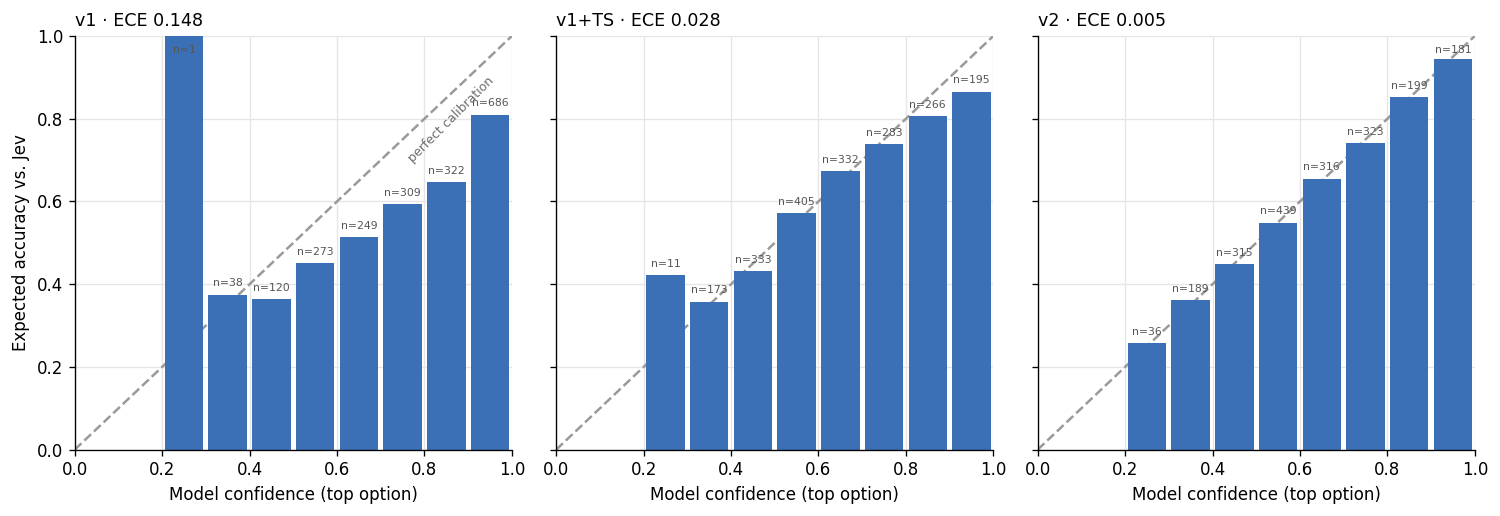

In [16]:
fig = reliability_panels([(f"v1 · ECE {v1_metrics['ece']:.3f}", v1_bins),
                          (f"v1+TS · ECE {v1ts_metrics['ece']:.3f}", v1ts_bins),
                          (f"v2 · ECE {v2_metrics['ece']:.3f}", v2_bins)],
                         f"{SAVE_DIR}/reliability_v1_v2.png")
plt.show()

## Is the difference real? (paired bootstrap, 95% intervals)
`diff` is the second model minus the first. For agreement, positive is better. For ECE, KL and Brier, **negative is better**.

In [17]:
s_v1, s_v1ts, s_v2 = (row_stats(d, eval_s["target"]) for d in (v1_dists, v1_ts_dists, v2_dists))
print("v2 vs v1")
print(paired_bootstrap(s_v1, s_v2).round(4).to_string(index=False))
print("\nv2 vs v1+TS  (the real test)")
print(paired_bootstrap(s_v1ts, s_v2).round(4).to_string(index=False))

v2 vs v1
   metric    diff  ci_low  ci_high              real?
agreement -0.0135 -0.0275   0.0010 no (could be luck)
      ece -0.1432 -0.1483  -0.1282                yes
       kl -0.1753 -0.1882  -0.1624                yes
    brier -0.0499 -0.0551  -0.0447                yes

v2 vs v1+TS  (the real test)
   metric    diff  ci_low  ci_high              real?
agreement -0.0135 -0.0275   0.0010 no (could be luck)
      ece -0.0233 -0.0290  -0.0101                yes
       kl -0.0332 -0.0391  -0.0268                yes
    brier -0.0120 -0.0150  -0.0087                yes


In [18]:
import datetime
now = datetime.datetime.now().isoformat(timespec="minutes")
res_path = f"{SAVE_DIR}/results.csv"
results = pd.read_csv(res_path)
new = pd.DataFrame([
    {"version": "v1+TS", "model": MODEL_ID, "method": f"v1 + temperature scaling, T={T_v1} fit on val", **v1ts_metrics, "run_at": now},
    {"version": "v2", "model": MODEL_ID, "method": f"QLoRA distillation (soft labels), r={LORA_R}, lr={LR}, {len(train_rows)} rows", **v2_metrics, "run_at": now},
    {"version": "v2+TS", "model": MODEL_ID, "method": f"v2 + temperature scaling, T={T_v2} fit on val", **v2ts_metrics, "run_at": now},
])
results = pd.concat([results[~results["version"].isin(new["version"])], new], ignore_index=True)
results.to_csv(res_path, index=False)

out = eval_s[["id", "kind", "domain", "target"]].copy()
out["v2_pred"] = [p.tolist() for p in v2_dists]
out["v2_letter_mass"] = v2_mass
out.to_parquet(f"{SAVE_DIR}/preds_v2.parquet")
model.save_pretrained(f"{SAVE_DIR}/v2_adapter")
print(results.drop(columns=["model", "run_at"]).round(3).to_string(index=False))

version                                                        method    n  agreement  expected_acc  mean_conf   ece    kl  brier  letter_mass
     v0                                                     zero-shot 1998      0.349         0.341      0.930 0.590 5.025  0.821        0.725
  prior                                     Jev average per (kind, k) 1998      0.399         0.387      0.415 0.028 0.493  0.255          NaN
     v1            QLoRA SFT hard labels, r=16, lr=0.0002, 19393 rows 1998      0.788         0.629      0.776 0.148 0.319  0.126        1.000
  v1+TS                    v1 + temperature scaling, T=1.9 fit on val 1998      0.788         0.629      0.637 0.028 0.177  0.088        1.000
     v2 QLoRA distillation (soft labels), r=16, lr=0.0002, 19393 rows 1998      0.774         0.624      0.625 0.005 0.144  0.077        1.000
  v2+TS                    v2 + temperature scaling, T=1.0 fit on val 1998      0.774         0.624      0.625 0.005 0.144  0.077        1.000